<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [hopforge](https://github.com/Gokaran-Shukla/hopforge) · MIT License — any reuse must keep this copyright notice and credit the author.

# 18 · Step by step: a multi-orbital model, then orbital/spin Hall and torques in bilayers and moiré bilayers

1. Slater-Koster p-orbital layers: a heavy layer and a ferromagnet.
2. Atomic L·S spin-orbit coupling and exchange.
3. Orbital and spin Hall conductivities of each layer.
4. Stack them into a bilayer (heterostructure).
5. Layer-resolved Edelstein responses.
6. Spin-orbit, orbital and self-torques (Kubo-Středa: field-like and damping-like parts).
7. The same in a twisted (moiré) bilayer.

The torque decomposition follows Freimuth, Blügel & Mokrousov (PRB 2014) and Go et al. (orbital torque).
These are model calculations for building intuition, not material predictions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline
from hopforge import response as R, moire as MO
from hopforge.models._util import LS_matrix

## Step 1-2: build the two layers with Slater-Koster parameters

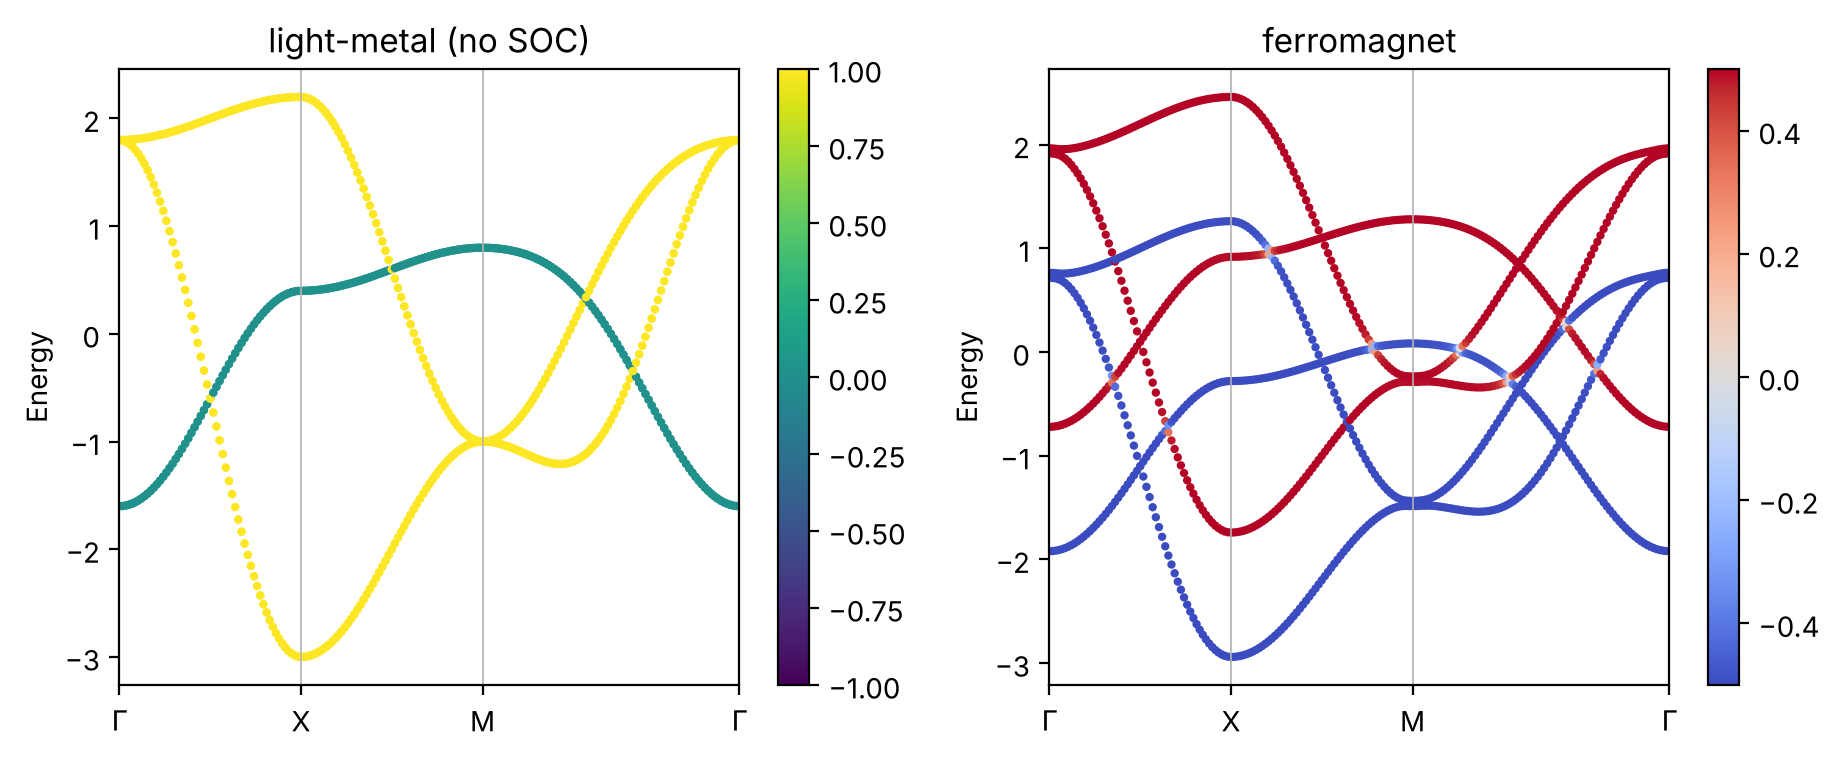

In [2]:
def p_layer(pps, ppp, pps2, ppp2, lso=0.0, J=0.0, eps_z=0.0, name="layer"):
    lat = hf.Lattice([[1, 0], [0, 1]], [("X:px", [0, 0]), ("X:py", [0, 0]), ("X:pz", [0, 0])])
    m = hf.Model(lat, spinful=True, name=name)
    m.add_slater_koster({"pps": pps, "ppp": ppp}, 1)          # nearest neighbours
    m.add_slater_koster({"pps": pps2, "ppp": ppp2}, 2)        # next-nearest (px-py mixing)
    if lso: m.add_onsite_matrix(LS_matrix(1, lso), ["X:px", "X:py", "X:pz"])
    if J:   m.add_exchange(J, (0, 0, 1))
    m.add_onsite(eps_z, "X:pz")
    m.special_points = {"G": np.zeros(2), "X": np.array([0.5, 0]), "M": np.array([0.5, 0.5])}
    return m
heavy = p_layer(1.0, -0.3, 0.3, -0.1, lso=0.0, name="light-metal (no SOC)")
ferro = p_layer(0.8, -0.25, 0.2, -0.08, lso=0.05, J=0.6, name="ferromagnet")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
heavy.plot_bands(["G", "X", "M", "G"], ax=ax[0], weights=heavy.orbital_operator('z') @ heavy.orbital_operator('z'), cmap="viridis")
ferro.plot_bands(["G", "X", "M", "G"], ax=ax[1], weights=ferro.spin_operator('z'));

## Step 3: orbital vs spin Hall of each layer
The orbital Hall effect needs no SOC (Go et al., PRL 121, 086602 (2018)).

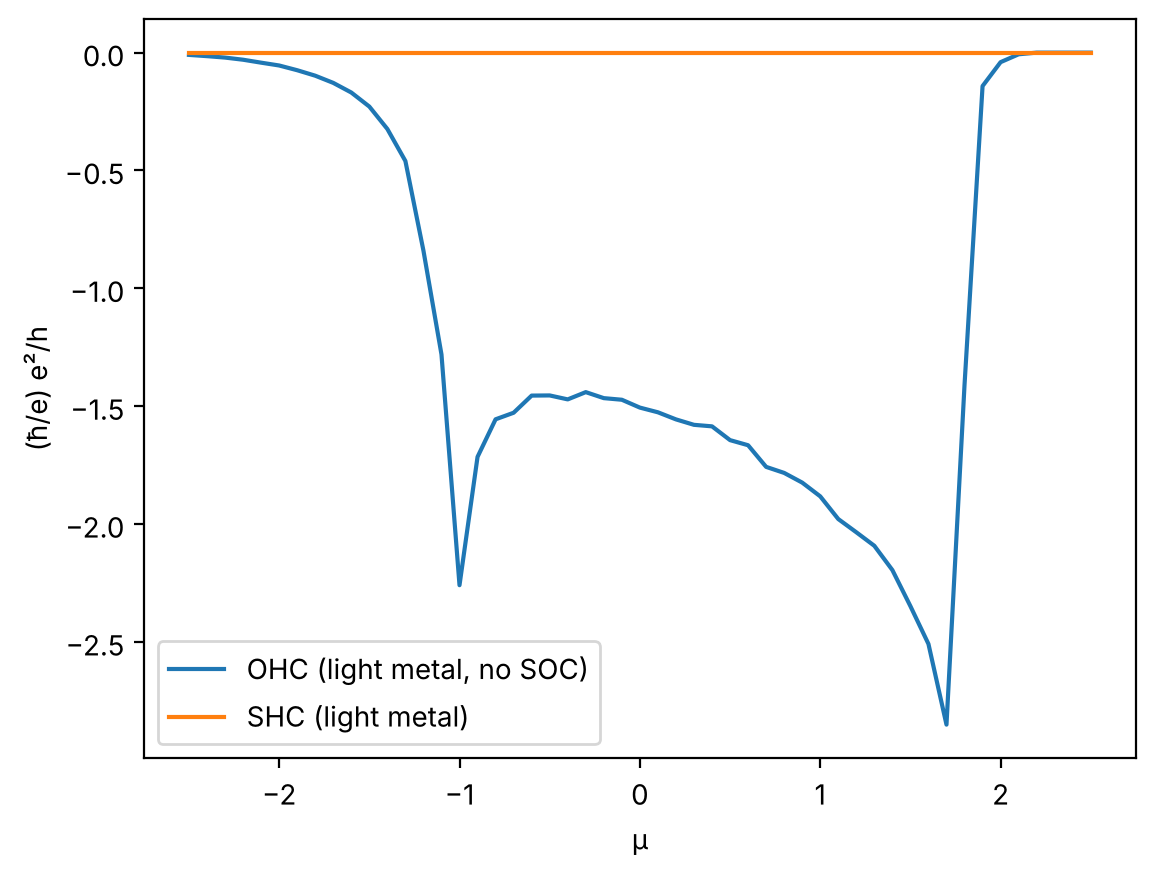

In [3]:
mus = np.linspace(-2.5, 2.5, 51)
ohc = hf.orbital_hall(heavy, mus, nk=80, eta=0.02, n_jobs=-1).sigma
shc = hf.spin_hall(heavy, mus, nk=80, eta=0.02, n_jobs=-1).sigma
plt.plot(mus, ohc, label="OHC (light metal, no SOC)"); plt.plot(mus, shc, label="SHC (light metal)")
plt.legend(); plt.xlabel("μ"); plt.ylabel("(ħ/e) e²/h");

## Step 4: stack the layers into a bilayer
`moire.bilayer` assembles any two commensurate layers, with Slater-Koster interlayer hopping between their orbitals.

<Model 'FM / light-metal bilayer': dim=2, orbitals=6, spinful=True, bands=12>  bottom (FM) orbitals: [0, 1, 2]  top orbitals: [3, 4, 5]


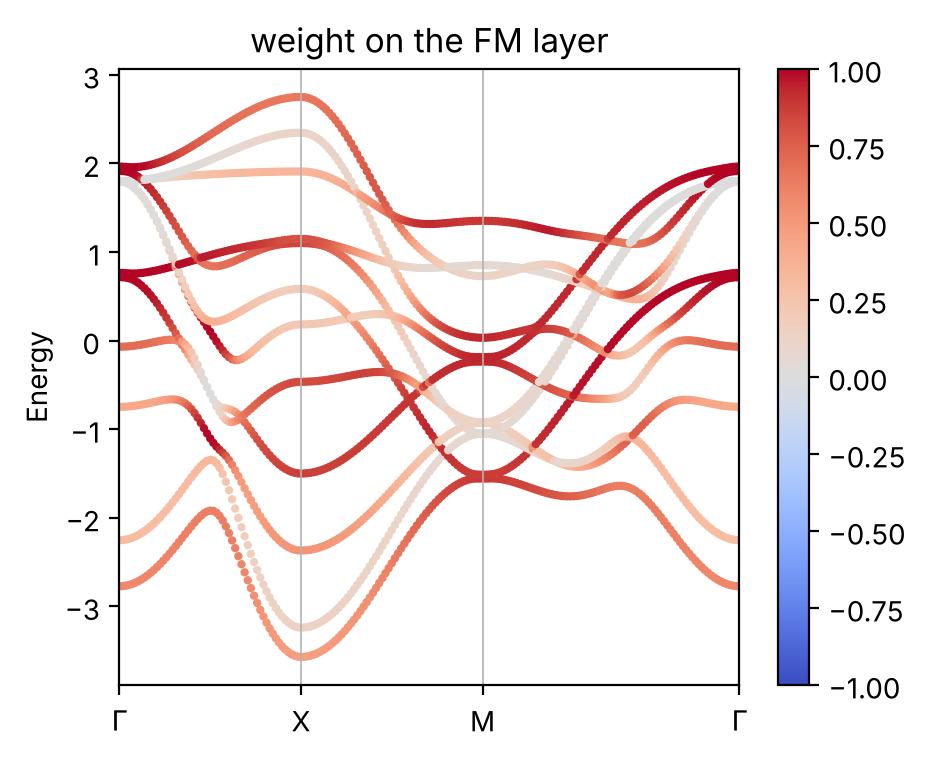

In [4]:
bi = MO.bilayer(ferro, heavy, d=1.0, interlayer={"pps": 0.4, "ppp": -0.1}, cutoff=1.6, name="FM / light-metal bilayer")
L = bi.info["layers"]
print(bi, " bottom (FM) orbitals:", L["bottom"], " top orbitals:", L["top"])
bi.special_points = ferro.special_points
bi.plot_bands(["G", "X", "M", "G"], weights=bi.projector(L["bottom"]), cmap="coolwarm", title="weight on the FM layer");

## Step 5: layer-resolved Edelstein responses (E ∥ x)

In [5]:
mu = 0.3
for lay in ("bottom", "top"):
    for name, op in (("S_y", bi.spin_operator('y')), ("L_y", bi.orbital_operator('y'))):
        A = R.layer_operator(bi, L[lay], op)
        r = R.kubo_streda(bi, A, "x", mu=mu, Gamma=0.05, nk=80, n_jobs=-1)
        print(f"{lay:6s} <{name}>: Fermi surface {r['fermi_surface'][0]:+.4f}   Fermi sea {r['fermi_sea'][0]:+.4f}")

bottom <S_y>: Fermi surface +0.0228   Fermi sea -0.0000


bottom <L_y>: Fermi surface +1.1768   Fermi sea -0.0000


top    <S_y>: Fermi surface +0.0026   Fermi sea -0.0000


top    <L_y>: Fermi surface -0.3650   Fermi sea -0.0000


## Step 6: torques on the ferromagnet: SOT, orbital torque and self-torque
The **self-torque** is the torque a current in a ferromagnet exerts on its own magnetisation. By symmetry it **vanishes in a centrosymmetric ferromagnet**, so we first check that. Then we break inversion inside the FM with an interface (orbital-Rashba) term $\gamma\,\hat d$ that hybridises $p_z$ with $p_{x,y}$. Finally we compare with the torque on the same FM inside the bilayer, which adds the angular momentum injected from the other layer.

In [6]:
Jex = 0.6
def with_orbital_rashba(m, gamma):
    m = m.copy()
    m.add_neighbors(lambda d: gamma * d[0], 1, ["X:pz"], ["X:px"])
    m.add_neighbors(lambda d: gamma * d[1], 1, ["X:pz"], ["X:py"])
    return m
cases = {"FM alone (centrosymmetric)": (ferro, None),
         "FM alone + interface term (self-torque)": (with_orbital_rashba(ferro, 0.3), None),
         "FM inside the bilayer": (bi, L["bottom"])}
for name, (sys_, orbs) in cases.items():
    T = R.torkance(sys_, (0, 0, 1), Jex, "x", mu=mu, Gamma=0.05, nk=80, orbitals=orbs, n_jobs=-1)
    print(f"{name:40s} FL(FS) {T['fermi_surface_FL'][0]:+.4f}  DL(FS) {T['fermi_surface_DL'][0]:+.4f}  "
          f"FL(sea) {T['fermi_sea_FL'][0]:+.4f}  DL(sea) {T['fermi_sea_DL'][0]:+.4f}")

FM alone (centrosymmetric)               FL(FS) +0.0000  DL(FS) +0.0000  FL(sea) -0.0000  DL(sea) +0.0000


FM alone + interface term (self-torque)  FL(FS) -0.0581  DL(FS) -0.0061  FL(sea) -0.0000  DL(sea) +0.0039


FM inside the bilayer                    FL(FS) +0.0273  DL(FS) +0.0029  FL(sea) -0.0000  DL(sea) -0.0008


The centrosymmetric ferromagnet gives exactly zero, as symmetry requires. Breaking inversion produces a self-torque, and the bilayer adds torques driven by the angular momentum (spin and orbital) coming from the neighbouring layer.

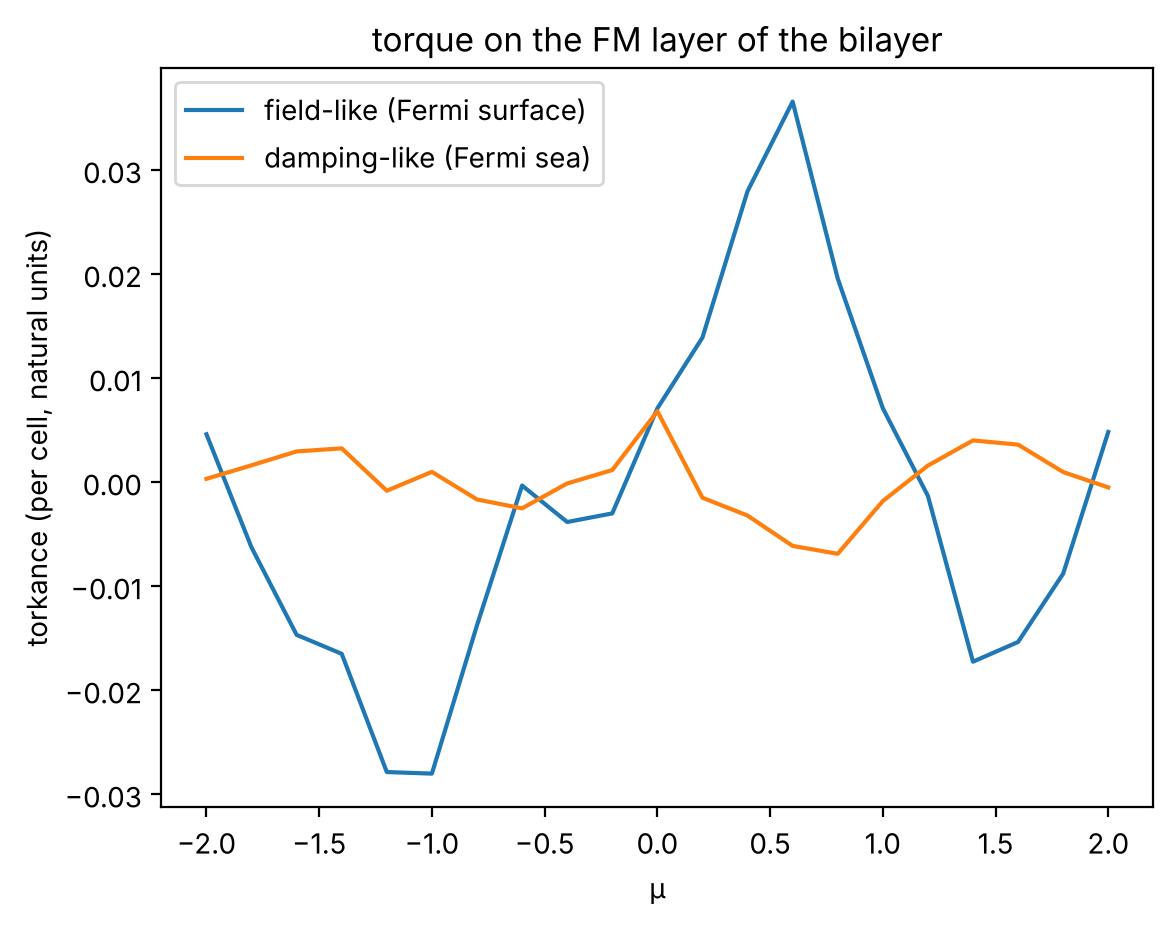

In [7]:
mus = np.linspace(-2.0, 2.0, 21)
T = R.torkance(bi, (0, 0, 1), Jex, "x", mu=mus, Gamma=0.05, nk=60, orbitals=L["bottom"], n_jobs=-1)
plt.plot(mus, T["fermi_surface_FL"], label="field-like (Fermi surface)")
plt.plot(mus, T["fermi_sea_DL"], label="damping-like (Fermi sea)")
plt.legend(); plt.xlabel("μ"); plt.ylabel("torkance (per cell, natural units)"); plt.title("torque on the FM layer of the bilayer");

## Step 7: a twisted (moiré) bilayer
The same workflow runs on a commensurate twisted bilayer. `rotate_model` rotates the lattice, the p-orbital Slater-Koster blocks and the spin frame. Here two graphene layers at 13.2°, with an exchange field on the bottom layer and Rashba-like proximity SOC on the top.

<Model 'twisted 13.17 deg': dim=2, orbitals=76, spinful=True, bands=152>


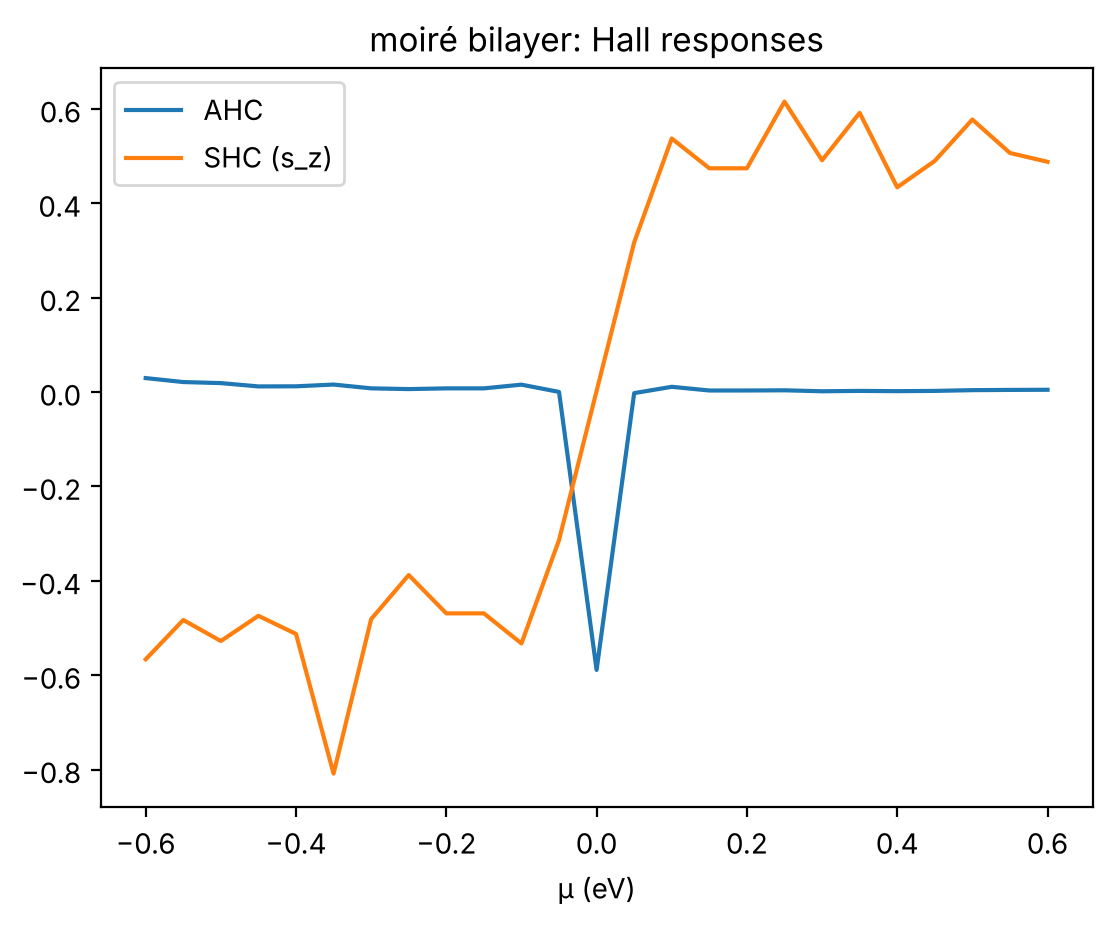

In [8]:
g = MO.graphene_layer().make_spinful()
gF = g.copy(); gF.add_exchange(0.1, (0, 0, 1))
gR = g.copy(); gR.add_rashba(0.05 * 2.7 / 2.7, 1)
theta, L1, L2 = MO.commensurate_hexagonal(2, 1)
b1, b2 = g.lat.vectors[1][:2], g.lat.vectors[1][:2] - g.lat.vectors[0][:2]
S = np.array([L1[0]*b1 + L1[1]*b2, L2[0]*b1 + L2[1]*b2])
tw = MO.bilayer(gF, MO.rotate_model(gR, theta), S, 3.35, MO.moon_koshino(), 6.0, name=f"twisted {np.degrees(theta):.2f} deg")
print(tw)
ahc = hf.anomalous_hall(tw, np.linspace(-0.6, 0.6, 25), nk=24, eta=0.01, n_jobs=-1)
she = hf.spin_hall(tw, np.linspace(-0.6, 0.6, 25), nk=24, eta=0.01, n_jobs=-1)
plt.plot(ahc.mu, ahc.sigma, label="AHC"); plt.plot(she.mu, she.sigma, label="SHC (s_z)")
plt.legend(); plt.xlabel("μ (eV)"); plt.title("moiré bilayer: Hall responses");

In [9]:
T = R.torkance(tw, (0, 0, 1), 0.1, "x", mu=0.2, Gamma=0.02, nk=16, orbitals=tw.info["layers"]["bottom"], n_jobs=-1)
print("moiré bilayer torque on the magnetic layer: FL =", T["fermi_surface_FL"][0], " DL =", T["fermi_sea_DL"][0])

moiré bilayer torque on the magnetic layer: FL = -0.0401193919087669  DL = -0.0010364781887356766


## Exercises
1. Turn on SOC in the light-metal layer and separate the spin-torque and orbital-torque contributions.
2. Reverse the magnetisation and check which torque components are even or odd in m.
3. Scan the twist angle (m = 1, 2, 3) and plot the torkance versus θ.

---
## Quiz 18: Orbitronics in bilayers and moire

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [10]:
quiz = hf.Quiz(18)
quiz.interactive()

In [11]:
quiz.show()

=== Quiz 18: Orbitronics, torques and moire bilayers ===

Q1. The orbital Hall effect can be large in
   (a) insulators only
   (b) light metals without SOC, via orbital hybridisation
   (c) only heavy metals
   (d) superconductors only

Q2. Atomic SOC in a p shell is
   (a) an exchange field
   (b) lambda sigma_z
   (c) a hopping
   (d) lambda L.S

Q3. `moire.bilayer(bottom, top, ...)` builds
   (a) a lead
   (b) a flake
   (c) a supercell model of two layers with Slater-Koster interlayer hopping
   (d) a ribbon

Q4. Layer-resolved responses use operators
   (a) the velocity only
   (b) P A P with P the projector on one layer's orbitals
   (c) the DOS
   (d) the full A only

Q5. In the Kubo-Streda decomposition the Fermi-surface term scales as
   (a) Gamma^0 always
   (b) Gamma
   (c) 1/Gamma (tau)
   (d) Gamma^2

Q6. The Fermi-sea (intrinsic) term
   (a) is independent of Gamma for small Gamma and involves interband coherence
   (b) needs leads
   (c) scales as 1/Gamma
   (d) vanishe

In [12]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0